In [1]:
# OPTIONAL: change to your project folder if needed
import os
print("Before:", os.getcwd())
# os.chdir(r"C:\Users\Pranav\OneDrive\Desktop\mask_alert_project")  # <- uncomment + set your path
print("Now at:", os.getcwd())


Before: C:\Users\Pranav\OneDrive\Desktop\mask_alert_project
Now at: C:\Users\Pranav\OneDrive\Desktop\mask_alert_project


In [2]:
!pip install --quiet opencv-python matplotlib simpleaudio tensorflow==2.* scikit-learn
!pip install --quiet face-recognition dlib-bin


In [3]:
import os, glob, sys

needed = ["email_alert.py", "known_faces", "dataset"]
print("Exists:")
for item in needed:
    print(f" - {item:<20} ->", "OK" if os.path.exists(item) else "MISSING")

print("\nSome example images under known_faces:")
print(glob.glob("known_faces/**/**/*.jpg", recursive=True)[:5])
print("\nModel file present?", os.path.exists("mask_detector_model.h5"))


Exists:
 - email_alert.py       -> OK
 - known_faces          -> OK
 - dataset              -> OK

Some example images under known_faces:
['known_faces\\bharath\\bharath (3).jpg', 'known_faces\\bharath\\bharath (4).jpg', 'known_faces\\bharath\\bharath (5).jpg', 'known_faces\\bharath\\bharath.jpg', 'known_faces\\gokul\\6.jpg']

Model file present? True


In [4]:
import os, numpy as np, matplotlib.pyplot as plt, pickle

from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, AveragePooling2D, Dropout, Flatten, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelBinarizer
from sklearn.model_selection import train_test_split

INIT_LR = 1e-4
EPOCHS  = 10
BS      = 32
IMAGE_SIZE = (224, 224)

dataset_dir = "dataset"
categories  = ["with_mask", "without_mask"]


In [5]:
print("[INFO] Loading images...")
data, labels = [], []

for category in categories:
    path = os.path.join(dataset_dir, category)
    for img in os.listdir(path):
        img_path = os.path.join(path, img)
        try:
            image = load_img(img_path, target_size=IMAGE_SIZE, color_mode="rgb")
            image = img_to_array(image)
            data.append(image)
            labels.append(category)
        except Exception as e:
            # skip unreadable images
            pass

data = np.array(data, dtype="float32") / 255.0

# Encode labels
lb = LabelBinarizer()
labels = lb.fit_transform(labels)
labels = to_categorical(labels)

(trainX, testX, trainY, testY) = train_test_split(
    data, labels, test_size=0.2, stratify=labels, random_state=42
)

print("Train:", trainX.shape, " Test:", testX.shape)


[INFO] Loading images...


C:\Users\Pranav\AppData\Local\Programs\Python\Python310\lib\site-packages\PIL\Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Train: (6042, 224, 224, 3)  Test: (1511, 224, 224, 3)


In [6]:
from tensorflow.keras.applications import MobileNetV2

baseModel = MobileNetV2(weights="imagenet", include_top=False,
                        input_tensor=Input(shape=(224, 224, 3)))

head = baseModel.output
head = AveragePooling2D(pool_size=(7, 7))(head)
head = Flatten()(head)
head = Dense(128, activation="relu")(head)
head = Dropout(0.5)(head)
head = Dense(2, activation="softmax")(head)

model = Model(inputs=baseModel.input, outputs=head)
for layer in baseModel.layers:
    layer.trainable = False

opt = Adam(learning_rate=INIT_LR, decay=INIT_LR / EPOCHS)
model.compile(loss="binary_crossentropy", optimizer=opt, metrics=["accuracy"])


In [8]:
import os
from tensorflow.keras.models import load_model

# Full path to your pretrained model
MODEL_DIR = r"C:\Users\Pranav\OneDrive\Desktop\mask_alert_project"
MODEL_PATH = os.path.join(MODEL_DIR, "final_model.h5")

# Always load pretrained model
if os.path.exists(MODEL_PATH):
    print(f"[INFO] Loading pretrained model from {MODEL_PATH} ...")
    model = load_model(MODEL_PATH)
    print("[INFO] Model loaded successfully. Ready for detection.")
else:
    raise FileNotFoundError(f"[ERROR] Could not find model at {MODEL_PATH}. Please train and save it first.")


[INFO] Loading pretrained model from C:\Users\Pranav\OneDrive\Desktop\mask_alert_project\final_model.h5 ...
[INFO] Model loaded successfully. Ready for detection.


In [10]:
import pickle, numpy as np
import matplotlib.pyplot as plt
import os

# Save model + label binarizer
model.save("mask_detector_model.h5")
with open("label_binarizer.pickle", "wb") as f:
    f.write(pickle.dumps(lb))

# Use training history variable (replace 'history' with the one you used in model.fit)
try:
    history_data = H.history   # if you used H = model.fit(...)
except NameError:
    try:
        history_data = history.history   # if you used history = model.fit(...)
    except NameError:
        history_data = None

# Plot training history if available
if history_data:
    plt.figure(figsize=(8,6))

    if "loss" in history_data:
        N = len(history_data["loss"])
        plt.plot(np.arange(0, N), history_data["loss"], label="train_loss")

    if "val_loss" in history_data:
        N_val = len(history_data["val_loss"])
        plt.plot(np.arange(0, N_val), history_data["val_loss"], label="val_loss")

    if "accuracy" in history_data:
        N_acc = len(history_data["accuracy"])
        plt.plot(np.arange(0, N_acc), history_data["accuracy"], label="train_acc")

    if "val_accuracy" in history_data:
        N_vacc = len(history_data["val_accuracy"])
        plt.plot(np.arange(0, N_vacc), history_data["val_accuracy"], label="val_acc")

    plt.title("Training Loss and Accuracy")
    plt.xlabel("Epoch #")
    plt.ylabel("Loss/Accuracy")
    plt.legend(loc="lower left")
    plt.show()
else:
    print("⚠️ No training history found. Did you run model.fit()?")

print("Saved:", os.path.exists("mask_detector_model.h5"))


⚠️ No training history found. Did you run model.fit()?
Saved: True


In [12]:
import email_alert
email_alert.send_email_alert("pranav", "known")


[INFO] Email sent successfully.


In [14]:
import smtplib
from email.mime.multipart import MIMEMultipart
from email.mime.text import MIMEText
from email.mime.base import MIMEBase
from email import encoders
import os

def send_email_alert(name, is_known=False, screenshot_path=None):
    sender = "your_email@gmail.com"      # change this
    receiver = "receiver_email@gmail.com" # change this
    password = "your_password"            # app password if Gmail

    # subject line
    if is_known:
        subject = f"Known person detected: {name}"
    else:
        subject = f"Unknown person detected: {name}"

    # create email
    msg = MIMEMultipart()
    msg["From"] = sender
    msg["To"] = receiver
    msg["Subject"] = subject

    body = f"Person detected: {name}"
    msg.attach(MIMEText(body, "plain"))

    # attach screenshot if provided
    if screenshot_path and os.path.exists(screenshot_path):
        with open(screenshot_path, "rb") as f:
            mime = MIMEBase("application", "octet-stream")
            mime.set_payload(f.read())
            encoders.encode_base64(mime)
            mime.add_header("Content-Disposition", f"attachment; filename={os.path.basename(screenshot_path)}")
            msg.attach(mime)

    # send email
    server = smtplib.SMTP("smtp.gmail.com", 587)
    server.starttls()
    server.login(sender, password)
    server.sendmail(sender, receiver, msg.as_string())
    server.quit()


In [15]:
# Install missing packages (run only once if needed)
# !pip install opencv-python matplotlib simpleaudio tensorflow==2.* scikit-learn face-recognition dlib-bin

import os, cv2, time, pickle, warnings
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import img_to_array

import face_recognition
import simpleaudio as sa

# Ignore some deprecation warnings
warnings.filterwarnings("ignore", category=UserWarning, module="face_recognition_models")

print("[INFO] Environment ready.")


C:\Users\Pranav\AppData\Local\Programs\Python\Python310\lib\site-packages\face_recognition_models\__init__.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


[INFO] Environment ready.


In [16]:
# Load your trained model (make sure mask_detector_model.h5 exists in this folder)
model = load_model("mask_detector_model.h5")

# Create screenshots folder
os.makedirs("screenshots", exist_ok=True)

# Known people mapping
known_info = {
    "gokul": {"name": "Gokul Nathan M", "year": "III", "department": "ECE"},
    "pranav": {"name": "Pranav UP", "year": "III", "department": "ECE"},
    "bharath": {"name": "Bharath A", "year": "III", "department": "ECE"},
    "sathik": {"name": "Sathik Mansur B", "year": "III", "department": "MZ"}
}

print("[INFO] Model loaded and ready.")


[INFO] Model loaded and ready.


In [17]:
known_face_encodings, known_face_names = [], []
base_path = "known_faces"   # make sure this folder exists

for folder_name in os.listdir(base_path):
    folder_path = os.path.join(base_path, folder_name)
    if os.path.isdir(folder_path):
        for filename in os.listdir(folder_path):
            if filename.lower().endswith((".jpg",".jpeg",".png")):
                image_path = os.path.join(folder_path, filename)
                img = face_recognition.load_image_file(image_path)
                enc = face_recognition.face_encodings(img)
                if enc:
                    known_face_encodings.append(enc[0])
                    known_face_names.append(folder_name.lower())

print(f"[INFO] Loaded {len(known_face_encodings)} known faces.")


[INFO] Loaded 26 known faces.


In [18]:
from IPython.display import display, clear_output
import matplotlib.pyplot as plt

import email_alert  # using your module

def play_alert_sound():
    try:
        wave_obj = sa.WaveObject.from_wave_file("alert.wav")
        wave_obj.play()
    except Exception as e:
        print("Sound playback failed:", e)

def classify_mask(frame, box):
    top, right, bottom, left = box
    face = frame[top:bottom, left:right]
    face = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)
    face = cv2.resize(face, (224, 224))
    face = img_to_array(face)
    face = preprocess_input(face)
    face = np.expand_dims(face, axis=0)
    (mask, without_mask) = model.predict(face, verbose=0)[0]
    return (mask, without_mask)


alert_cooldowns = {}  # person_key -> last alert time (sec)

def run_detection_jupyter(max_seconds=None):
    cap = cv2.VideoCapture(0, cv2.CAP_DSHOW)
    if not cap.isOpened():
        print("Could not open camera. Close other apps using webcam and retry.")
        return

    start = time.time()
    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                print("Frame grab failed.")
                break

            small = cv2.resize(frame, (0,0), fx=0.25, fy=0.25)
            rgb_small = cv2.cvtColor(small, cv2.COLOR_BGR2RGB)

            face_locations = face_recognition.face_locations(rgb_small)
            face_encodings = face_recognition.face_encodings(rgb_small, face_locations)

            for (enc, loc) in zip(face_encodings, face_locations):
                distances = face_recognition.face_distance(known_face_encodings, enc)
                min_dist = np.min(distances) if distances.size > 0 else 1.0

                if min_dist < 0.45:
                    idx = int(np.argmin(distances))
                    name_key = known_face_names[idx]
                    display_name = known_info.get(name_key, {}).get("name", name_key.title())
                else:
                    name_key = "unknown"
                    display_name = "Unknown"

                top, right, bottom, left = [v*4 for v in loc]
                mask, without_mask = classify_mask(frame, (top, right, bottom, left))

                if mask > without_mask:
                    label, color = "Mask", (0,255,0)
                else:
                    label, color = "No Mask", (0,0,255)

                text = f"{display_name} | {label}"
                cv2.rectangle(frame, (left, top), (right, bottom), color, 2)
                cv2.putText(frame, text, (left, top-10), cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)

                if label == "No Mask":
                    now = time.time()
                    if now - alert_cooldowns.get(name_key, 0) >= 60:
                        os.makedirs("screenshots", exist_ok=True)
                        snap = f"screenshots/{name_key}_{int(now)}.jpg"
                        cv2.imwrite(snap, frame)
                        play_alert_sound()
                        if name_key == "unknown":
                            email_alert.send_email_alert("unknown", screenshot_path=snap, is_known=False)
                        else:
                            email_alert.send_email_alert(name_key, is_known=True)
                        alert_cooldowns[name_key] = now

            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            plt.figure(figsize=(8,6))
            plt.imshow(rgb); plt.axis("off")
            clear_output(wait=True)
            display(plt.gcf())
            plt.close()

            if max_seconds and (time.time() - start) > max_seconds:
                print("⏱️ Stopping after", max_seconds, "seconds.")
                break

    except KeyboardInterrupt:
        print("Interrupted by user.")
    finally:
        cap.release()


In [19]:
# Option A: run until you interrupt the cell (stop button / Kernel > Interrupt)
# run_detection_jupyter()

# Option B: auto-stop after N seconds (useful in Jupyter)
from IPython.display import display, clear_output
import matplotlib.pyplot as plt

import email_alert  # using your module

alert_cooldowns = {}  # person_key -> last alert time (sec)

def run_detection_jupyter(max_seconds=None):
    # CAP_DSHOW helps on Windows
    cap = cv2.VideoCapture(0, cv2.CAP_DSHOW)
    if not cap.isOpened():
        print(" Could not open camera. Close other apps using webcam and retry.")
        return

    start = time.time()
    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                print("Frame grab failed.")
                break

            small = cv2.resize(frame, (0,0), fx=0.25, fy=0.25)
            rgb_small = cv2.cvtColor(small, cv2.COLOR_BGR2RGB)

            face_locations = face_recognition.face_locations(rgb_small)
            face_encodings = face_recognition.face_encodings(rgb_small, face_locations)

            for (enc, loc) in zip(face_encodings, face_locations):
                # identify person
                distances = face_recognition.face_distance(known_face_encodings, enc)
                min_dist = np.min(distances) if distances.size > 0 else 1.0

                if min_dist < 0.45:
                    idx = int(np.argmin(distances))
                    name_key = known_face_names[idx]
                    display_name = known_info.get(name_key, {}).get("name", name_key.title())
                else:
                    name_key = "unknown"
                    display_name = "Unknown"

                # scale back bbox
                top, right, bottom, left = [v*4 for v in loc]
                mask, without_mask = classify_mask(frame, (top, right, bottom, left))

                if mask > without_mask:
                    label, color = "Mask", (0,255,0)
                else:
                    label, color = "No Mask", (0,0,255)

                text = f"{display_name} | {label}"
                cv2.rectangle(frame, (left, top), (right, bottom), color, 2)
                cv2.putText(frame, text, (left, top-10), cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)

                # alerts for No Mask
                if label == "No Mask":
                    now = time.time()
                    if now - alert_cooldowns.get(name_key, 0) >= 60:
                        os.makedirs("screenshots", exist_ok=True)
                        snap = f"screenshots/{name_key}_{int(now)}.jpg"
                        cv2.imwrite(snap, frame)
                        play_alert_sound()
                        if name_key == "unknown":
                            email_alert.send_email_alert("unknown", screenshot_path=snap, is_known=False)
                        else:
                            email_alert.send_email_alert(name_key, is_known=True)
                        alert_cooldowns[name_key] = now

            # show inline (Jupyter)
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            plt.figure(figsize=(8,6))
            plt.imshow(rgb); plt.axis("off")
            clear_output(wait=True)
            display(plt.gcf())
            plt.close()

            # stop options
            if max_seconds and (time.time() - start) > max_seconds:
                print("⏱️ Stopping after", max_seconds, "seconds.")
                break

    except KeyboardInterrupt:
        print("Interrupted by user.")
    finally:
        cap.release()

# Example: auto-stop after 30 seconds
# run_detection_jupyter(max_seconds=30)


In [22]:
import importlib
import email_alert

# reload the module so Jupyter picks up your changes
importlib.reload(email_alert)


<module 'email_alert' from 'C:\\Users\\Pranav\\OneDrive\\Desktop\\mask_alert_project\\email_alert.py'>

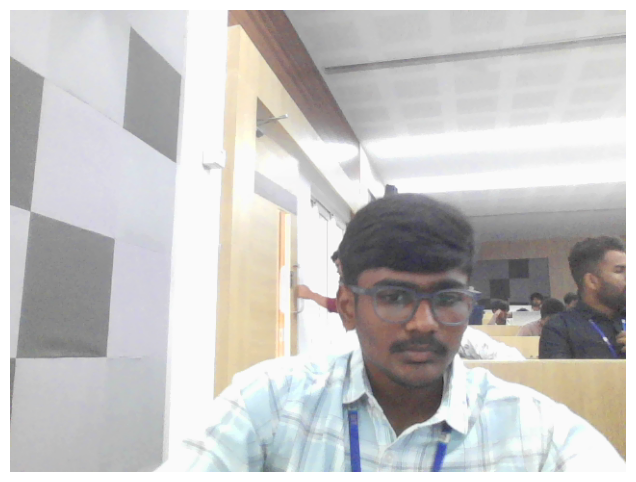

SMTPAuthenticationError: (535, b'5.7.8 Username and Password not accepted. For more information, go to\n5.7.8  https://support.google.com/mail/?p=BadCredentials d9443c01a7336-2490375a591sm91668615ad.60 - gsmtp')

In [28]:
run_detection_jupyter()